# Everything about Ensemble Learning (Exploited)

One passenger list, 891 people, and one question: who survived? A single decision tree answers it in a few splits, but it changes its mind whenever the data shifts slightly. This notebook grows that tree into a crowd (bagging, Random Forest, boosting, voting, stacking), works out **why** a crowd of weak models beats one strong-looking model, and checks every claim with the same cross-validation.

**Objectives**
1. Who survived, and which patterns can a model learn from the passenger list?
2. How does one decision tree choose its splits, and why does it overfit?
3. Why should combining many models work at all, and when does it stop working?
4. How do bagging and Random Forest reduce variance, and boosting reduce bias?
5. Can different algorithms vote, or learn to trust each other (stacking)?
6. Which ensemble wins on this data, and what does it rely on?

**Data** → [Kaggle competition](https://www.kaggle.com/competitions/titanic) · 891 passengers with outcome · 418 to predict · metric: accuracy

# [1/12] Setup

Set every knob once in the top cell → later cells only read them, and nothing is written by default

In [ ]:
"""Optional · Edit the settings, then run all cells. Explanations: README.md

[1/11] DATA_DIR: competition data folder
    Default = '/kaggle/input/titanic'
[2/11] WORK_DIR: folder for the submission file
    Default = '/kaggle/working'
[3/11] N_FOLDS / N_REPEATS: stratified folds, and how many times the split is reshuffled
    Default = 5 / 3
[4/11] SEED: random seed
    Default = 42
[5/11] TREE_DEPTHS: depths tried for the single decision tree
    Default = 1 … 12
[6/11] N_TREES: trees in every bagging / forest / boosting model and in the learning curves
    Default = 300
[7/11] RF_PARAMS: Random Forest settings
    Default = sqrt of the features per split, leaves of at least 2 passengers
[8/11] ADA_PARAMS: AdaBoost settings (decision stumps)
    Default = learning rate 0.5
[9/11] GB_PARAMS / XGB_PARAMS: gradient boosting settings
    Default = depth 3, learning rate 0.05, 80% of rows per tree
[10/11] LEARNING_RATES: learning rates compared in the boosting curves
    Default = (0.01, 0.05, 0.2, 1.0)
[11/11] SAVE_SUBMISSION: predict all test passengers and write submission.csv
    Default = False
    For example:
        SAVE_SUBMISSION = True
"""
DATA_DIR        = '/kaggle/input/titanic'
WORK_DIR        = '/kaggle/working'
N_FOLDS         = 5
N_REPEATS       = 3
SEED            = 42
TREE_DEPTHS     = range(1, 13)
N_TREES         = 300
RF_PARAMS       = {
    'max_features':     'sqrt',
    'min_samples_leaf': 2,
}
ADA_PARAMS      = {
    'learning_rate':    0.5,
}
GB_PARAMS       = {
    'learning_rate':    0.05,
    'max_depth':        3,
    'subsample':        0.8,
}
XGB_PARAMS      = {
    'learning_rate':    0.05,
    'max_depth':        3,
    'subsample':        0.8,
    'colsample_bytree': 0.8,
    'reg_lambda':       1.0,
}
LEARNING_RATES  = (0.01, 0.05, 0.2, 1.0)
SAVE_SUBMISSION = False

SUBMISSION_FILE    = f'{WORK_DIR}/submission.csv'
SUBMISSION_PREVIEW = 10
TARGET             = 'Survived'
PAD                = 30
PALETTE            = {'main': 'black', 'flag': 'red', 'soft': 'grey'}
RARE_TITLES        = ['Dr', 'Rev', 'Col', 'Major', 'Capt', 'Sir', 'Lady', 'the Countess', 'Jonkheer', 'Don', 'Dona']
NUM_COLS           = ['Pclass', 'Age', 'SibSp', 'Parch', 'FamilySize', 'LogFare', 'IsFemale', 'IsAlone', 'HasCabin', 'AgeMissing']
CAT_COLS           = ['Title', 'Embarked', 'Deck']

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import binom

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, GradientBoostingClassifier,
                              RandomForestClassifier, StackingClassifier, VotingClassifier)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

sns.set_theme(style='darkgrid', palette='gray')

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')


def survival_rate(df, col):
    return df.groupby(col, observed=True)[TARGET].agg(['mean', 'size']).rename(columns={'mean': 'survival rate', 'size': 'passengers'})

# [2/12] Data

Load the passenger lists and read the gaps → `Cabin` is mostly empty, `Age` is missing for 1 in 5, and both gaps carry information

In [ ]:
train_raw = pd.read_csv(f'{DATA_DIR}/train.csv')
test_raw  = pd.read_csv(f'{DATA_DIR}/test.csv')
show_block('Outputs', {'train_raw': train_raw.shape, 'test_raw': test_raw.shape,
                       'survived': f'{train_raw[TARGET].sum()} of {len(train_raw)} ({train_raw[TARGET].mean():.1%})'})

In [ ]:
display(train_raw.head())

**Question:** Which columns have gaps, and should those passengers or columns be dropped?

**Answer:** No. Only 3 columns have gaps: `Cabin` (687 passengers, 77%), `Age` (177, 20%) and `Embarked` (2). Dropping the passengers without an age would throw away 1 in 5 rows, and the gaps are not random:
- no recorded age → 29% survived, against 41% with an age
- no recorded cabin → 30% survived, against 67% with a cabin

→ Keep every passenger: fill `Age` with the median inside each training fold and add an `AgeMissing` flag; turn `Cabin` into `HasCabin` and `Deck`. The gap itself becomes a feature.

In [ ]:
missing = pd.DataFrame({'train missing': train_raw.isna().sum(), 'test missing': test_raw.isna().sum()})
missing = missing[(missing > 0).any(axis=1)].fillna(0).astype(int)
missing['train %'] = (missing['train missing'] / len(train_raw) * 100).round(1)
display(missing.sort_values('train missing', ascending=False))
display(pd.DataFrame({'survival rate': [train_raw.loc[train_raw['Age'].isna(), TARGET].mean(),
                                        train_raw.loc[train_raw['Age'].notna(), TARGET].mean(),
                                        train_raw.loc[train_raw['Cabin'].isna(), TARGET].mean(),
                                        train_raw.loc[train_raw['Cabin'].notna(), TARGET].mean()]},
                     index=['Age missing', 'Age known', 'Cabin missing', 'Cabin known']).round(3))

# [3/12] Survival patterns

Compare survival rates by sex, class, title, family size and age → "women and children first" is visible in the data, and class decides the rest

**Question:** Who survived?

$$\text{survival rate}(g) = \frac{\text{survivors in group } g}{\text{passengers in group } g}$$
- the dashed line in each chart is the overall rate, 38.4%: a bar above it means the group did better than average
- Analogy → a school's pass rate by class: the overall rate hides that one class passed almost entirely and another barely did

**Answer:** Women and children first, then the rich:
- **Sex** → women 74%, men 19%
- **Class** → 1st class 63%, 2nd 47%, 3rd 24%
- **Title** → Mrs 79%, Miss 70%, Master (boys) 58%, Mr 16%; children under 12 survived 58%
- **Sex × class** → women in 1st and 2nd class almost all survived (97%, 92%), women in 3rd class only half (50%); men in 2nd and 3rd class 16% and 13%
- **Family** → families of 2-4 did better (55-72%) than passengers alone (30%) or families of 5 and more (14-20%)
- **Port** → Cherbourg 55%: a port can't save anyone, so this most likely stands in for class

No single column tells the whole story: sex decides most outcomes, and class decides how far being a woman helped.

In [ ]:
eda = train_raw.assign(Title=train_raw['Name'].str.extract(r',\s*([^\.]+)\.')[0].replace(RARE_TITLES, 'Rare')
                                                .replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'}),
                       FamilySize=(train_raw['SibSp'] + train_raw['Parch'] + 1).clip(upper=7),
                       AgeBand=pd.cut(train_raw['Age'], [0, 12, 18, 30, 45, 60, 80]))
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, col in zip(axes.flat, ['Sex', 'Pclass', 'Title', 'FamilySize', 'AgeBand', 'Embarked']):
    rates = survival_rate(eda, col)
    ax.bar(rates.index.astype(str), rates['survival rate'], color=PALETTE['main'])
    ax.axhline(train_raw[TARGET].mean(), color=PALETTE['flag'], linestyle='--')
    for x, (rate, size) in enumerate(zip(rates['survival rate'], rates['passengers'])):
        ax.text(x, rate + 0.02, f'n={size}', ha='center', fontsize=8)
    ax.set(title=f'Survival rate by {col}', ylim=(0, 1.05), ylabel='survival rate')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
display(pd.crosstab([eda['Sex'], eda['Pclass']], eda[TARGET], normalize='index').rename(columns={0: 'died', 1: 'survived'}).round(3))

# [4/12] Features

Turn names, cabins and families into model columns → title, family size, deck and missing-value flags, all built row by row so no passenger leaks into another

**Question:** Which new columns can we build, and why these?

| Feature | Built from | Why |
|---|---|---|
| `Title` | `Name` → Mr, Mrs, Miss, Master, Rare | sex **and** age in one word: "Master" means a boy |
| `FamilySize`, `IsAlone` | `SibSp + Parch + 1` | travelling alone and travelling as a family of 8 both hurt |
| `Deck`, `HasCabin` | first letter of `Cabin`, `U` when unknown | a recorded cabin is a proxy for wealth and for location on the ship |
| `LogFare` | $\log(1 + \text{Fare})$ | fares run from \$0 to \$512; the log keeps the few expensive tickets from dominating linear models |
| `AgeMissing` | `Age` is empty | the gap itself predicts survival ([2/12]) |

Every step uses only that passenger's own row. Steps that **learn** from data (median age, one-hot categories, scaling) sit in a pipeline and are refit inside each training fold.

**Answer:** 13 columns per passenger: 10 numeric and 3 categorical, which become **26 model columns** after one-hot encoding. `Title` splits the passengers into 517 Mr, 185 Miss, 126 Mrs, 40 Master and 23 Rare; deck letters shared by fewer than 10 passengers are merged into one "infrequent" column, so no column describes a handful of people.

In [ ]:
def prepare(df):
    title = (df['Name'].str.extract(r',\s*([^\.]+)\.')[0]
             .replace(RARE_TITLES, 'Rare').replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'}))
    return pd.DataFrame({
        'Pclass':     df['Pclass'],
        'Age':        df['Age'],
        'SibSp':      df['SibSp'],
        'Parch':      df['Parch'],
        'FamilySize': df['SibSp'] + df['Parch'] + 1,
        'LogFare':    np.log1p(df['Fare']),
        'IsFemale':   (df['Sex'] == 'female').astype(int),
        'IsAlone':    (df['SibSp'] + df['Parch'] == 0).astype(int),
        'HasCabin':   df['Cabin'].notna().astype(int),
        'AgeMissing': df['Age'].isna().astype(int),
        'Title':      title,
        'Embarked':   df['Embarked'],
        'Deck':       df['Cabin'].str[0].fillna('U'),
    })


X      = prepare(train_raw)
X_test = prepare(test_raw)
y      = train_raw[TARGET].to_numpy()
display(X.head())
show_block('Outputs', {'X': X.shape, 'X_test': X_test.shape, 'titles': X['Title'].value_counts().to_dict()})

In [ ]:
def make_preprocessor(scale=False):
    numeric     = make_pipeline(SimpleImputer(strategy='median'), StandardScaler()) if scale else SimpleImputer(strategy='median')
    categorical = make_pipeline(SimpleImputer(strategy='most_frequent'),
                                OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=10, sparse_output=False))
    return ColumnTransformer([('num', numeric, NUM_COLS), ('cat', categorical, CAT_COLS)], verbose_feature_names_out=False)


tree_prep     = make_preprocessor().fit(X)
feature_names = tree_prep.get_feature_names_out()
X_tree        = pd.DataFrame(tree_prep.transform(X), columns=feature_names)
show_block('Outputs', {'model matrix': X_tree.shape, 'columns': ', '.join(feature_names)})

# [5/12] Baselines

Score a majority guess, a one-rule model and logistic regression with repeated stratified cross-validation → the bar every ensemble has to clear

**Question:** What is a good score here?

$$\text{accuracy} = \frac{\text{correct predictions}}{\text{passengers}}$$
- the competition metric. Analogy → a weather forecaster's hit rate: how many days the "rain / no rain" call was right

$$\text{ROC-AUC} = P\big(\hat p(\text{random survivor}) > \hat p(\text{random victim})\big)$$
- $\hat p$ → the model's survival probability. AUC asks whether the model **ranks** survivors above victims, regardless of where the 50% cut sits. 0.5 = coin flip, 1.0 = perfect ranking
- Analogy → a doctor ordering patients by urgency: the order can be good even before deciding who gets a bed

**Repeated stratified K-fold** → 5 folds that each keep the 38 / 62 survival split, reshuffled `N_REPEATS` times = 15 scores per model. With only 891 passengers, one lucky split can move accuracy by 3 points; 15 splits average that luck away, like tasting a soup from several spoons instead of one.

**Answer:** 
- **Majority guess** → "everyone died" is already right **61.6%** of the time, the floor any model must beat
- **One rule** → "women survive, men die" reaches **78.7%** with one question
- **Logistic regression** → all features: **82.2%** accuracy, ROC-AUC **0.871**

The fold-to-fold standard deviation is about 2 points for every model → differences below about 1 point between two models are luck of the split, not skill.

In [ ]:
cv      = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=SEED)
cv_once = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
results = {}
models  = {}


def evaluate(name, model, family):
    scoring = ['accuracy', 'roc_auc'] if hasattr(model, 'predict_proba') else ['accuracy']
    scores  = cross_validate(model, X, y, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    results[name] = {'family':         family,
                     'CV accuracy':    scores['test_accuracy'].mean(),
                     'std':            scores['test_accuracy'].std(),
                     'CV ROC-AUC':     scores['test_roc_auc'].mean() if 'test_roc_auc' in scores else np.nan,
                     'train accuracy': scores['train_accuracy'].mean()}
    results[name]['overfit gap'] = results[name]['train accuracy'] - results[name]['CV accuracy']
    models[name] = model
    return results[name]


def tree_model(estimator):
    return make_pipeline(make_preprocessor(), estimator)


def scaled_model(estimator):
    return make_pipeline(make_preprocessor(scale=True), estimator)

In [ ]:
baselines = {
    'Majority guess (everyone dies)': (tree_model(DummyClassifier(strategy='most_frequent')), 'baseline'),
    'One rule: women survive':        (make_pipeline(ColumnTransformer([('sex', 'passthrough', ['IsFemale'])]),
                                                     DecisionTreeClassifier(max_depth=1)), 'baseline'),
    'Logistic regression':            (scaled_model(LogisticRegression(max_iter=1000)), 'single model'),
}
for i, (name, (model, family)) in enumerate(baselines.items(), 1):
    print(f'[{i}/{len(baselines)}] {name}')
    evaluate(name, model, family)
display(pd.DataFrame(results).T.round(4))

# [6/12] One decision tree

Watch a tree pick its splits by hand, then let it grow → the first split is sex, and a deep tree memorises the training passengers

**Question:** How does a tree decide which question to ask first?

$$\text{Gini}(S) = 1 - \sum_{c} p_c^2 \qquad\qquad \text{Entropy}(S) = -\sum_{c} p_c \log_2 p_c$$
- $S$ → a group of passengers, $p_c$ → the share of class $c$ (survived / died) in it
- **Gini** → the chance that two passengers drawn at random from the group have different outcomes. 0 = everyone shares one fate
- **Entropy** → how many yes/no questions you still need, on average, to learn a passenger's outcome. 1 bit = a 50 / 50 group
- Analogy → a bag of marbles: all red is pure (0); half red, half blue is as mixed as it gets

$$\text{Gain} = \text{Impurity}(S) - \sum_{k} \frac{|S_k|}{|S|}\,\text{Impurity}(S_k)$$
- $S_k$ → the groups after the split, weighted by their size
- the tree tries every column and threshold and keeps the split with the largest gain
- Analogy → the game "Guess Who?": the best first question ("is it a woman?") removes the most uncertainty in one go

**Answer:** Not sex, but "is the passenger a **Mr**?": Gini gain **0.1427** against 0.1396 for sex, and the same order by information gain (0.226 vs 0.218 bits). "Mr" means *adult* man, so it also moves the boys (Master, 58% survival) to the side of the women; the sex split leaves them among the men. Mr survival is 16%, everyone else 70%. Class (0.049) and a recorded cabin (0.048) come a distant third. The depth-3 tree below starts with exactly this split.

In [ ]:
def gini(labels):
    p = np.bincount(labels, minlength=2) / len(labels)
    return 1 - np.sum(p ** 2)


def entropy(labels):
    p = np.bincount(labels, minlength=2) / len(labels)
    p = p[p > 0]
    return -np.sum(p * np.log2(p))


candidates = {'IsFemale = 1':         X['IsFemale'] == 1,
              'Title = Mr':           X['Title'] == 'Mr',
              'Pclass = 3':           X['Pclass'] == 3,
              'HasCabin = 1':         X['HasCabin'] == 1,
              'Age < 10':             X['Age'] < 10,
              'LogFare > median':     X['LogFare'] > X['LogFare'].median()}
rows = {}
for name, mask in candidates.items():
    mask = mask.to_numpy()
    rows[name] = {'yes': mask.sum(), 'survival if yes': y[mask].mean(), 'survival if no': y[~mask].mean(),
                  'Gini gain': gini(y) - (mask.mean() * gini(y[mask]) + (~mask).mean() * gini(y[~mask])),
                  'information gain': entropy(y) - (mask.mean() * entropy(y[mask]) + (~mask).mean() * entropy(y[~mask]))}
show_block('Outputs', {'Gini (all passengers)': f'{gini(y):.4f}', 'entropy (all passengers)': f'{entropy(y):.4f} bits'})
display(pd.DataFrame(rows).T.sort_values('Gini gain', ascending=False).round(4))

**Question:** How deep should the tree grow?

**Answer:** **Depth 4**, at 81.6% cross-validated accuracy. Beyond it, training accuracy keeps climbing (96% at depth 12) while cross-validated accuracy drifts down to 80.3%. An unlimited tree scores 98.9% on the passengers it trained on and **78.9%** on new ones, below the one-rule model: a 20-point gap that is pure memorisation, like a student who learns last year's answers by heart.

In [ ]:
depth_rows = {}
for depth in TREE_DEPTHS:
    scores = cross_validate(tree_model(DecisionTreeClassifier(max_depth=depth, random_state=SEED)), X, y, cv=cv,
                            scoring='accuracy', return_train_score=True, n_jobs=-1)
    depth_rows[depth] = {'train accuracy': scores['train_score'].mean(), 'CV accuracy': scores['test_score'].mean()}
depth_table = pd.DataFrame(depth_rows).T
best_depth  = int(depth_table['CV accuracy'].idxmax())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(depth_table.index, depth_table['train accuracy'], marker='o', color=PALETTE['soft'], label='train')
ax.plot(depth_table.index, depth_table['CV accuracy'], marker='o', color=PALETTE['main'], label='cross-validated')
ax.axvline(best_depth, color=PALETTE['flag'], linestyle='--', label=f'best depth = {best_depth}')
ax.set(xlabel='max_depth', ylabel='accuracy', title='One decision tree: deeper fits the training passengers, not new ones')
ax.legend()
plt.show()
display(depth_table.T.round(3))

In [ ]:
evaluate(f'Decision tree (depth {best_depth})', tree_model(DecisionTreeClassifier(max_depth=best_depth, random_state=SEED)), 'single model')
evaluate('Decision tree (unlimited)', tree_model(DecisionTreeClassifier(random_state=SEED)), 'single model')
small_tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_tree, y)
fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(small_tree, feature_names=feature_names, class_names=['died', 'survived'], filled=True, impurity=True,
          proportion=True, rounded=True, fontsize=9, ax=ax)
ax.set_title('Depth-3 tree on all passengers (value = [died, survived] share)')
plt.show()

**Question:** If one tree is decent, why is it not enough?

Grow 25 full trees, each on a slightly different random sample of the same passengers, and ask them all about the same validation passengers.

**Answer:** It changes its mind too easily. 25 trees, each grown on a bootstrap sample of the same 712 training passengers, score anywhere from **74.9% to 84.4%** on the same 179 validation passengers, and they are not unanimous on **69.3%** of them. Yet their **majority vote scores 83.2%**, better than almost any of them alone: the disagreement between trees is exactly what an ensemble feeds on.

In [ ]:
train_idx, val_idx = next(cv_once.split(X, y))
prep_fold = make_preprocessor().fit(X.iloc[train_idx])
X_fit, X_val = prep_fold.transform(X.iloc[train_idx]), prep_fold.transform(X.iloc[val_idx])
rng   = np.random.default_rng(SEED)
votes = np.array([DecisionTreeClassifier(random_state=k).fit(X_fit[s], y[train_idx][s]).predict(X_val)
                  for k, s in enumerate(rng.integers(0, len(train_idx), size=(25, len(train_idx))))])
single_acc   = (votes == y[val_idx]).mean(axis=1)
share_yes    = votes.mean(axis=0)
show_block('Outputs', {'validation passengers':           len(val_idx),
                       'single-tree accuracy (range)':    f'{single_acc.min():.3f} - {single_acc.max():.3f}',
                       'not unanimous':                   f'{((share_yes > 0) & (share_yes < 1)).mean():.1%}',
                       'majority vote of the 25 trees':   f'{((share_yes > 0.5) == y[val_idx]).mean():.3f}'})

# [7/12] Ensemble learning

Map the 5 ways to combine models and work out when a crowd beats an individual → only when the members make **different** mistakes

**Question:** What kinds of ensembles exist?

Two questions sort every ensemble: are the members trained **in parallel** (independently) or **in sequence** (each one fixes the last), and are they the **same algorithm** or **different ones**?

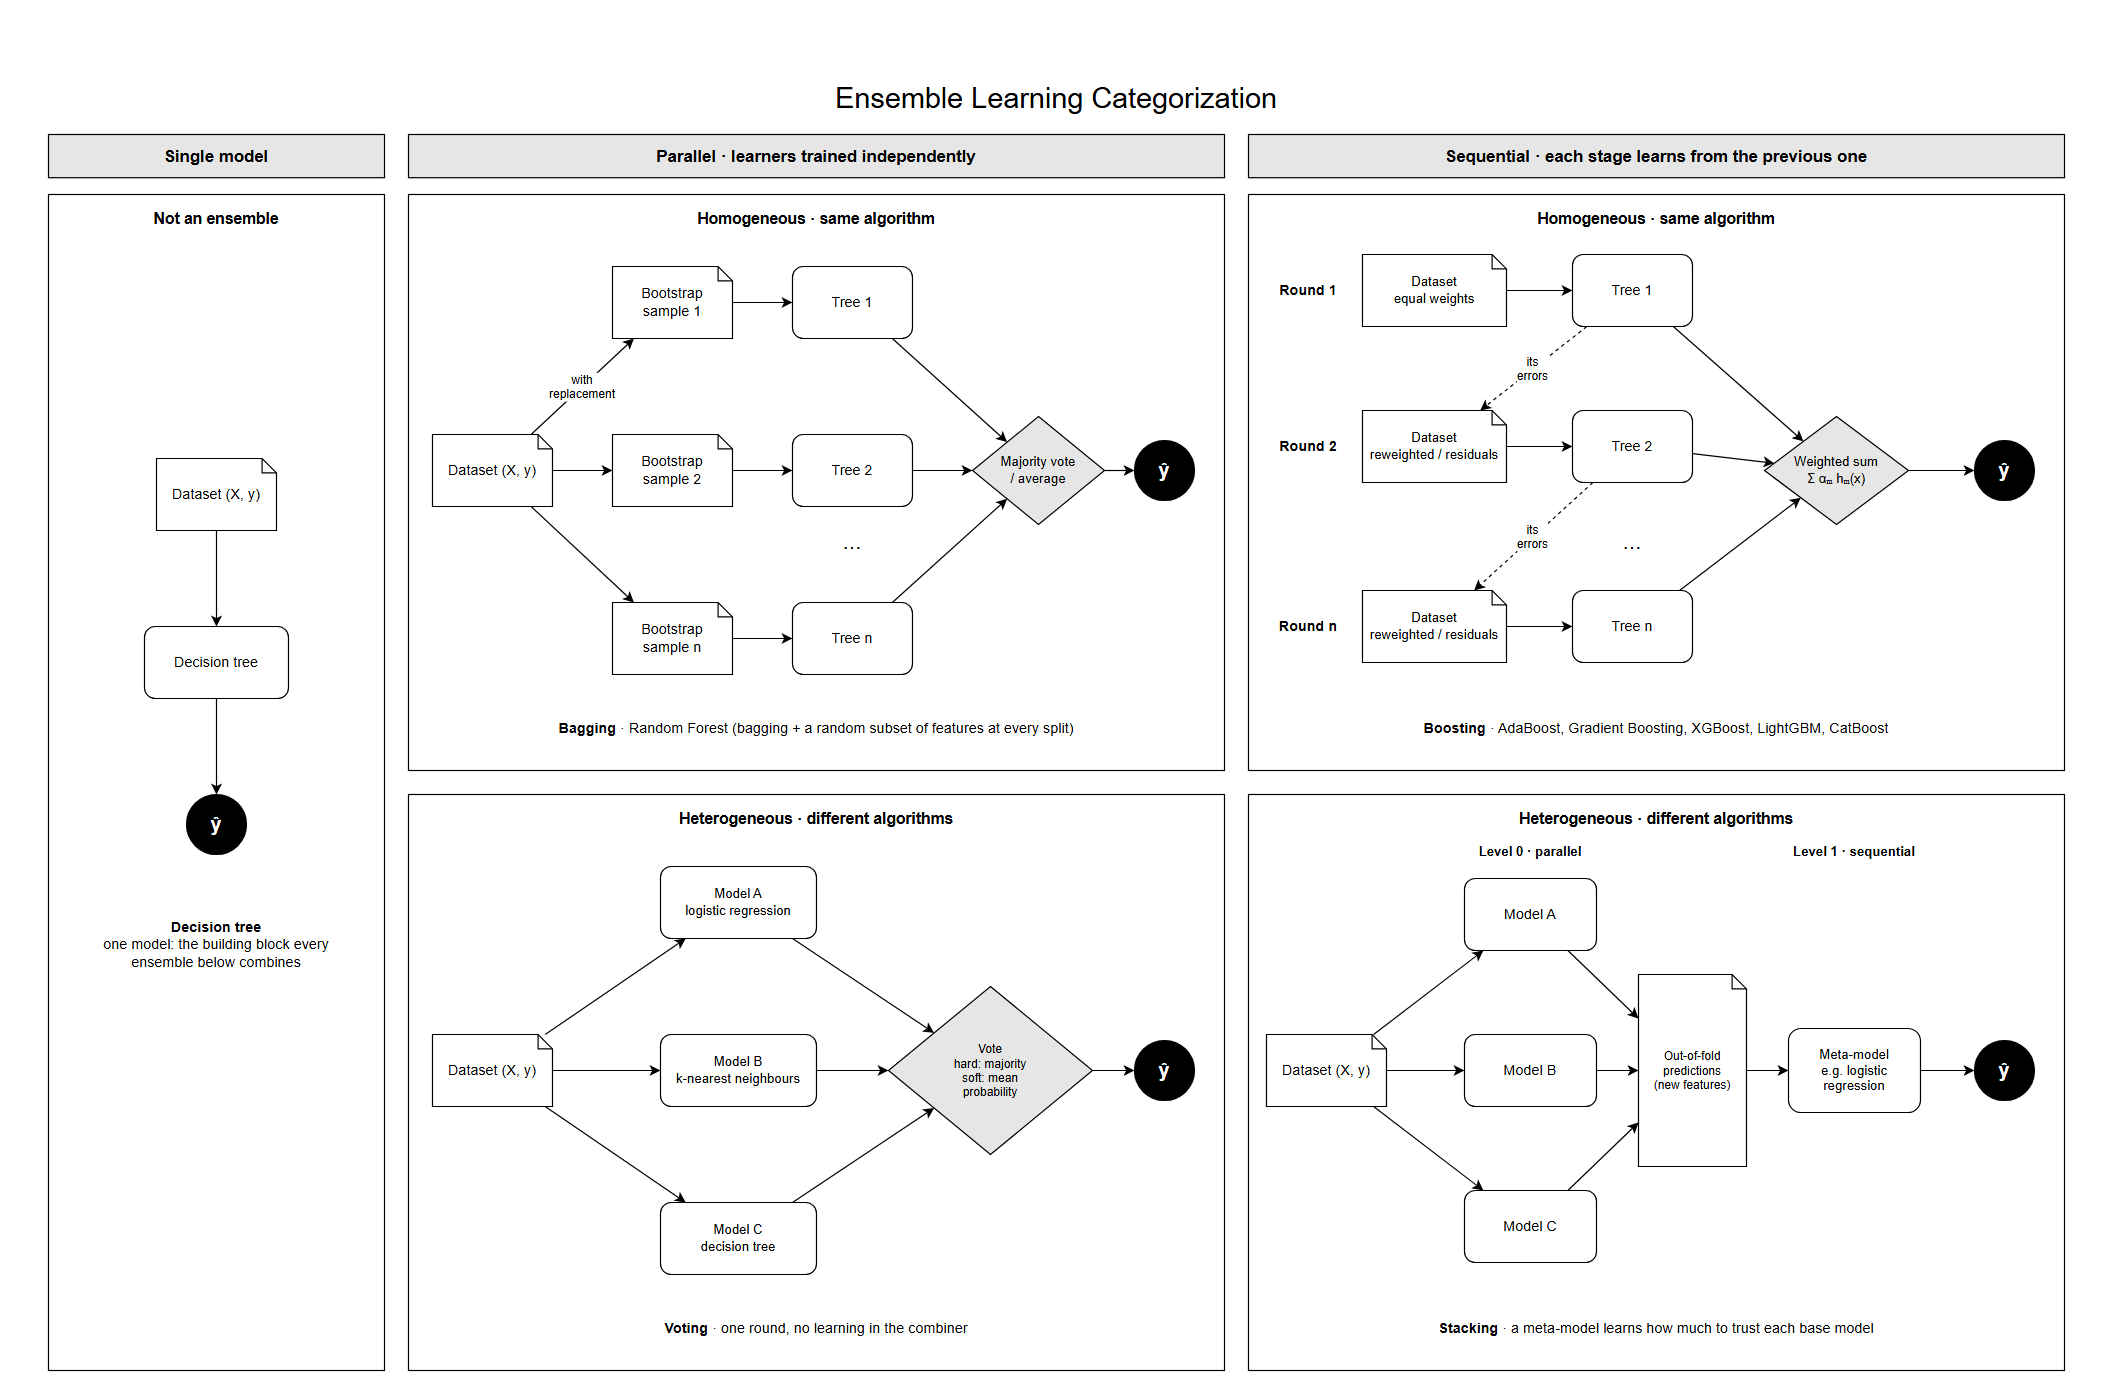

| | Parallel | Sequential |
|---|---|---|
| **Same algorithm** | **Bagging / Random Forest** → many trees on bootstrap samples, majority vote → lowers **variance** | **Boosting** → each tree focuses on what the previous ones got wrong, weighted sum → lowers **bias** |
| **Different algorithms** | **Voting** → logistic regression, k-NN, trees… vote once | **Stacking** → base models in parallel, then a meta-model learns how far to trust each |

**Question:** Why should a crowd of mediocre models beat one good one?

In 1906 Francis Galton asked 787 visitors at a country fair to guess the weight of an ox. No single guess was reliable, but the **median guess was 1,207 lb, against a true 1,198 lb**. Individual errors pointed in different directions and cancelled out.

$$P(\text{majority correct}) = \sum_{k > n/2}^{n} \binom{n}{k}\, p^k (1-p)^{n-k}$$
- $n$ → number of voters (models), $p$ → the accuracy of each one on its own
- $\binom{n}{k} p^k (1-p)^{n-k}$ → the chance that exactly $k$ of them are right (the binomial distribution)
- the sum → the chance that **more than half** are right, i.e. that the vote is right
- the catch: this assumes the voters are **independent**. 25 copies of the same model are one voter
- Analogy → asking 25 strangers for directions vs asking the same person 25 times

**Answer:** With truly independent voters the vote races towards 100%: 51 voters that are each right 65% of the time would be right together **98.6%** of the time. The 25 real trees reach only **83.2%** (red star), because they learned from the same passengers and repeat many of the same mistakes. That gap between the curve and the star is the whole story of ensembles: the gain is limited by **how alike the members are**, and every method below is a different way to make them less alike.

In [ ]:
voters = np.arange(1, 102, 2)
fig, ax = plt.subplots(figsize=(10, 4.5))
for p, style in [(0.55, ':'), (0.65, '--'), (0.75, '-')]:
    majority = [binom.sf(n // 2, n, p) for n in voters]
    ax.plot(voters, majority, linestyle=style, color=PALETTE['main'], label=f'independent voters, each {p:.0%} right')
ax.axhline(single_acc.mean(), color=PALETTE['flag'], linestyle='-.', label=f'one full tree on Titanic ({single_acc.mean():.0%})')
ax.scatter([25], [((share_yes > 0.5) == y[val_idx]).mean()], s=120, marker='*', color=PALETTE['flag'], zorder=3,
           label='25 real bootstrap trees, majority vote')
ax.set(xlabel='number of voters n', ylabel='P(majority is right)', ylim=(0.5, 1.01),
       title='Condorcet: a vote of independent models gets better with every voter')
ax.legend(fontsize=9)
plt.show()
show_block('Outputs', {'51 independent voters at 65%': f'{binom.sf(25, 51, 0.65):.3f}',
                       '25 real trees (correlated)':  f'{((share_yes > 0.5) == y[val_idx]).mean():.3f}'})

# [8/12] Bagging and Random Forest

Train many full trees on bootstrap samples and add feature sampling → averaging lowers variance, and decorrelating the trees lowers it further

**Question:** How can a model get more training sets out of one dataset?

$$P(\text{passenger left out of one bootstrap sample}) = \Big(1 - \frac{1}{n}\Big)^n \;\xrightarrow{n \to \infty}\; e^{-1} \approx 36.8\%$$
- a **bootstrap sample** draws $n$ passengers **with replacement**: some appear twice, about a third not at all
- the left-out passengers are **out-of-bag** (OOB): every tree has its own free validation set, no fold needed
- Analogy → a raffle where tickets go back in the drum after each draw: some names are called twice, some never

$$\text{Var}\big(\bar h\big) = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2$$
- $B$ → number of trees, $\sigma^2$ → how much one tree's prediction wobbles, $\rho$ → the average correlation between two trees, measured as Breiman did: how alike their right / wrong records are over the validation passengers
- more trees ($B \uparrow$) only shrink the second term; the first term $\rho\sigma^2$ stays → **correlation sets the floor**
- **Random Forest** → at every split a tree may only look at a random $\sqrt{p}$ of the $p$ columns, so the trees can't all start with "sex" → lower $\rho$
- Analogy → a jury: adding jurors who read the same newspaper adds little; jurors with different sources make a better verdict

**Answer:** 
- **Bootstrap** → $(1 - 1/891)^{891} = 0.3677$, and 200 real bootstrap samples leave out 36.76% ± 1.1% of the passengers, exactly as the formula says
- **Out-of-bag** → the forest's OOB accuracy (82.6%) lands close to its 15-fold accuracy (82.1%) at no extra cost
- **More trees** → both methods jump from 78.3% with 1 tree to 82.4% with 10, then plateau: **83.6%** for bagging, **82.5%** for Random Forest at 300 trees
- **Correlation** → on Titanic the √p rule does **not** decorrelate the trees: ρ = 0.43 against 0.44 for bagging, so Random Forest has no variance to win back and ends slightly behind

In [ ]:
n_rows  = len(X)
oob     = [(1 - np.isin(np.arange(n_rows), rng.integers(0, n_rows, n_rows))).mean() for _ in range(200)]
show_block('Outputs', {'(1 - 1/n)^n for n = 891':    f'{(1 - 1 / n_rows) ** n_rows:.4f}',
                       'left out, 200 real samples':  f'{np.mean(oob):.4f} ± {np.std(oob):.4f}'})

In [ ]:
def staged_vote_curves(estimator):
    curve, corr = np.zeros(N_TREES), []
    for train_idx, val_idx in cv_once.split(X, y):
        fitted = tree_model(clone(estimator)).fit(X.iloc[train_idx], y[train_idx])
        X_val  = fitted[0].transform(X.iloc[val_idx])
        feats  = getattr(fitted[-1], 'estimators_features_', [slice(None)] * N_TREES)
        probs  = np.array([tree.predict_proba(X_val[:, f])[:, 1] for tree, f in zip(fitted[-1].estimators_, feats)])
        curve += ((np.cumsum(probs, axis=0) / np.arange(1, N_TREES + 1)[:, None] > 0.5) == y[val_idx]).mean(axis=1)
        c      = np.corrcoef(np.where((probs > 0.5) == y[val_idx], 1.0, -1.0))
        corr.append(c[np.triu_indices_from(c, k=1)].mean())
    return curve / N_FOLDS, float(np.mean(corr))


forest_variants = {
    'Bagging (all columns per split)': BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=RF_PARAMS['min_samples_leaf']),
                                                         n_estimators=N_TREES, random_state=SEED),
    'Random Forest (√p columns per split)': RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, **RF_PARAMS),
}
curves, correlations = {}, {}
for i, (name, estimator) in enumerate(forest_variants.items(), 1):
    print(f'[{i}/{len(forest_variants)}] {name}')
    curves[name], correlations[name] = staged_vote_curves(estimator)

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for (name, curve), style in zip(curves.items(), ['--', '-']):
    ax.plot(np.arange(1, N_TREES + 1), curve, linestyle=style, color=PALETTE['main'], label=f'{name} · tree correlation ρ = {correlations[name]:.2f}')
ax.axhline(results[f'Decision tree (depth {best_depth})']['CV accuracy'], color=PALETTE['flag'], linestyle=':', label=f'best single tree (depth {best_depth})')
ax.set(xscale='log', xlabel='number of trees (log scale)', ylabel='CV accuracy', title='More trees: fast gains, then a plateau set by the correlation ρ')
ax.legend(fontsize=9)
plt.show()
display(pd.DataFrame({'1 tree': {k: v[0] for k, v in curves.items()}, '10 trees': {k: v[9] for k, v in curves.items()},
                      f'{N_TREES} trees': {k: v[-1] for k, v in curves.items()}, 'tree correlation ρ': correlations}).round(3))

**Question:** Random Forest's only change is the number of columns per split. Where is its sweet spot on this data?

**Answer:** A U-shape, with the default near the bottom: **1 column per split** scores best (84.1%) with the least alike trees (ρ = 0.36); √p = 5 columns scores 82.5%; all 26 columns (plain bagging) 83.6%.
- the signal sits in a few columns (title, sex, class). With 5 random columns a split often has to do without the best one, so each tree gets weaker, but it usually finds a close substitute (`Title_Mr` ↔ `IsFemale`), so the trees stay just as alike
- with 1 column per split the trees become almost random, truly different from each other, and the vote of 300 of them recovers the signal

These numbers come from one 5-fold split, and differences of about 1 point are within its noise → √p is a sensible default, not a law. The knob is worth tuning on each dataset.

In [ ]:
sweep = {}
for i, k in enumerate([1, 2, 3, 5, 8, 13, 20, None], 1):
    print(f'[{i}/8] columns per split = {k or "all"}')
    curve, rho = staged_vote_curves(RandomForestClassifier(n_estimators=N_TREES, max_features=k, random_state=SEED,
                                                           min_samples_leaf=RF_PARAMS['min_samples_leaf']))
    sweep[k or X_tree.shape[1]] = {'CV accuracy': curve[-1], 'tree correlation ρ': rho}
sweep = pd.DataFrame(sweep).T

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(sweep.index, sweep['CV accuracy'], marker='o', color=PALETTE['main'], label='accuracy (left axis)')
ax.axvline(np.sqrt(X_tree.shape[1]), color=PALETTE['flag'], linestyle='--', label='√p, the Random Forest default')
ax.set(xlabel='columns a tree may look at per split', ylabel=f'CV accuracy, {N_TREES} trees',
       title='Fewer columns per split → trees less alike, but each one weaker')
ax2 = ax.twinx()
ax2.plot(sweep.index, sweep['tree correlation ρ'], marker='s', linestyle=':', color=PALETTE['soft'], label='tree correlation ρ (right axis)')
ax2.set_ylabel('tree correlation ρ')
ax2.grid(False)
fig.legend(loc='lower center', bbox_to_anchor=(0.6, 0.15), fontsize=9)
plt.show()
display(sweep.T.round(3))

In [ ]:
evaluate('Bagging', tree_model(forest_variants['Bagging (all columns per split)']), 'bagging')
evaluate('Random Forest', tree_model(RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, **RF_PARAMS)), 'bagging')
oob_forest = tree_model(RandomForestClassifier(n_estimators=N_TREES, oob_score=True, random_state=SEED, **RF_PARAMS)).fit(X, y)
show_block('Outputs', {'Random Forest OOB accuracy': f'{oob_forest[-1].oob_score_:.4f}',
                       'Random Forest CV accuracy':  f'{results["Random Forest"]["CV accuracy"]:.4f}'})

# [9/12] Boosting

Chain small trees so each one corrects the previous ones → AdaBoost reweights the hard passengers, gradient boosting fits the remaining error, and the learning rate decides how fast it overfits

**Question:** How does AdaBoost decide which passengers deserve more attention?

$$\varepsilon_m = \sum_{i:\,h_m(x_i) \ne y_i} w_i \qquad \alpha_m = \tfrac12 \ln\frac{1 - \varepsilon_m}{\varepsilon_m} \qquad w_i \leftarrow w_i \, e^{\pm\alpha_m}$$
- $w_i$ → the weight of passenger $i$, starting equal ($1/n$) and always summing to 1
- $h_m$ → stump number $m$: a tree with one split. $\varepsilon_m$ → its **weighted** error rate
- $\alpha_m$ → its say in the final vote: a stump that is barely better than a coin ($\varepsilon \approx 0.5$) gets $\alpha \approx 0$
- $e^{+\alpha_m}$ for the passengers it got **wrong**, $e^{-\alpha_m}$ for the right ones → the next stump has to care about the mistakes
- final prediction → $\text{sign}\big(\sum_m \alpha_m h_m(x)\big)$, a weighted vote
- Analogy → a teacher who builds each new quiz from the questions the class got wrong last time

**Answer:** Each round has a harder job and gets less say:
- **Round 1** → "is the passenger a Mr?", ε = 0.218, α = 0.64
- **Round 2** → "is the deck known?", ε = 0.301, α = 0.42
- **Round 3** → "family of 5 or more?", ε = 0.421, α = 0.16: barely better than a coin, so barely heard

After every update the passengers just missed hold exactly **50%** of the weight, so the next stump can't ignore them. After 3 rounds the surprising cases dominate: women who died are 9% of the passengers but carry 18% of the weight, men who survived 12% → 25%.

In [ ]:
weights, rounds = np.full(len(y), 1 / len(y)), {}
for m in range(1, 4):
    stump   = DecisionTreeClassifier(max_depth=1).fit(X_tree, y, sample_weight=weights)
    miss    = stump.predict(X_tree) != y
    eps     = weights[miss].sum()
    alpha   = 0.5 * np.log((1 - eps) / eps)
    weights = weights * np.exp(np.where(miss, alpha, -alpha))
    weights = weights / weights.sum()
    rounds[f'round {m}'] = {'split': f'{feature_names[stump.tree_.feature[0]]} ≤ {stump.tree_.threshold[0]:.2f}',
                            'weighted error ε': round(eps, 4), 'say α': round(alpha, 4), 'passengers missed': int(miss.sum()),
                            'weight on the missed after update': round(weights[miss].sum(), 4)}
display(pd.DataFrame(rounds).T)
groups = train_raw['Sex'] + np.where(y == 1, ' · survived', ' · died')
display(pd.DataFrame({'share of passengers': groups.value_counts(normalize=True),
                      'share of weight after round 3': pd.Series(weights).groupby(groups.to_numpy()).sum()}).round(3))

**Question:** How does gradient boosting improve step by step, and what does the learning rate do?

$$F_m(x) = F_{m-1}(x) + \nu\, h_m(x) \qquad h_m \approx -\frac{\partial L}{\partial F} = y - \hat p_{m-1}(x)$$
- $F_m$ → the model's **log-odds** of survival after $m$ trees; $\hat p = 1 / (1 + e^{-F})$
- $h_m$ → a small tree fitted to the **residuals** $y - \hat p$: how far each passenger's current probability is from the truth
- $\nu$ → **learning rate**: each tree only takes a fraction of the step. Small $\nu$ = many careful steps; large $\nu$ = few bold ones that overshoot and memorise noise
- Analogy → tuning a guitar string: big twists reach the note fast but overshoot; small twists take longer and land on pitch

**Answer:** The learning rate trades speed for safety:
- **ν = 0.05** → the highest peak, 85.1% at tree 204, still 84.5% at 300
- **ν = 0.01** → still climbing at 300 trees (83.6%): too careful for this budget
- **ν = 0.2** → peaks early (84.7% at tree 76), then decays to 82.4%
- **ν = 1.0** → peaks at tree 2 (82.3%) and falls to 77.2% while training accuracy reaches 92-97%: every tree overshoots
- **AdaBoost with stumps** → train and validation stay within 1 point: a stump is too simple to memorise anyone

Over the 15 folds: Gradient Boosting **83.5%**, XGBoost 83.3%, AdaBoost 82.7%. Gradient boosting leads the family, but with a 10-point gap between train and validation accuracy.

In [ ]:
def staged_boosting(make_estimator):
    val_curve, train_curve = np.zeros(N_TREES), np.zeros(N_TREES)
    for train_idx, val_idx in cv_once.split(X, y):
        fitted = tree_model(make_estimator()).fit(X.iloc[train_idx], y[train_idx])
        X_fit, X_val = fitted[0].transform(X.iloc[train_idx]), fitted[0].transform(X.iloc[val_idx])
        val_curve   += np.array([(p == y[val_idx]).mean() for p in fitted[-1].staged_predict(X_val)])
        train_curve += np.array([(p == y[train_idx]).mean() for p in fitted[-1].staged_predict(X_fit)])
    return val_curve / N_FOLDS, train_curve / N_FOLDS


boost_curves = {}
for i, lr in enumerate(LEARNING_RATES, 1):
    print(f'[{i}/{len(LEARNING_RATES)}] gradient boosting · learning rate {lr}')
    boost_curves[lr] = staged_boosting(lambda: GradientBoostingClassifier(n_estimators=N_TREES, random_state=SEED,
                                                                         **{**GB_PARAMS, 'learning_rate': lr}))
print('[+] AdaBoost · stumps')
ada_curve = staged_boosting(lambda: AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=N_TREES,
                                                      random_state=SEED, **ADA_PARAMS))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for (lr, (val, train)), style in zip(boost_curves.items(), [':', '--', '-', '-.']):
    axes[0].plot(np.arange(1, N_TREES + 1), val, linestyle=style, color=PALETTE['main'], label=f'ν = {lr} · validation')
lr_max = max(LEARNING_RATES)
axes[0].plot(np.arange(1, N_TREES + 1), boost_curves[lr_max][1], color=PALETTE['flag'], label=f'ν = {lr_max} · train')
axes[0].set(xlabel='number of trees', ylabel='accuracy', title='Gradient boosting: the learning rate sets the pace', ylim=(0.75, 1.0))
axes[0].legend(fontsize=9)
axes[1].plot(np.arange(1, N_TREES + 1), ada_curve[0], color=PALETTE['main'], label='validation')
axes[1].plot(np.arange(1, N_TREES + 1), ada_curve[1], color=PALETTE['soft'], label='train')
axes[1].set(xlabel='number of stumps', ylabel='accuracy', title='AdaBoost with stumps: weak learners, slow overfitting', ylim=(0.75, 1.0))
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()
display(pd.DataFrame({f'ν = {lr}': {'best validation': val.max(), 'at tree': int(val.argmax()) + 1, f'validation at {N_TREES}': val[-1],
                                     f'train at {N_TREES}': train[-1]} for lr, (val, train) in boost_curves.items()}).round(3))

In [ ]:
boosters = {
    'AdaBoost (stumps)': tree_model(AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=N_TREES, random_state=SEED, **ADA_PARAMS)),
    'Gradient Boosting': tree_model(GradientBoostingClassifier(n_estimators=N_TREES, random_state=SEED, **GB_PARAMS)),
    'XGBoost':           tree_model(XGBClassifier(n_estimators=N_TREES, random_state=SEED, n_jobs=1, **XGB_PARAMS)),
}
for i, (name, model) in enumerate(boosters.items(), 1):
    print(f'[{i}/{len(boosters)}] {name}')
    evaluate(name, model, 'boosting')
display(pd.DataFrame(results).T.loc[list(boosters)].round(4))

# [10/12] Voting and Stacking

Combine different algorithms: let them vote, then train a meta-model on their predictions → the gain depends on how differently they err

**Question:** Do different algorithms make different mistakes?

The vote only helps where the members disagree. Below, each model's out-of-fold mistakes are compared pairwise: correlation 1 = they always fail on the same passengers, 0 = unrelated failures.

**Answer:** Not very. Their mistakes correlate **0.64-0.81**: the two tree ensembles overlap most (0.81), k-NN and Gradient Boosting least (0.64). **97 passengers fool all 4 models**, and 91 of them are men who survived (62) or women who died (29), the exceptions to "women and children first" that no column explains, and only 124 passengers split the models. A vote can fix at most those 124, and only where the majority happens to be right.

In [ ]:
base_models = {
    'Logistic regression': scaled_model(LogisticRegression(max_iter=1000)),
    'k-NN (k = 15)':       scaled_model(KNeighborsClassifier(n_neighbors=15)),
    'Random Forest':       tree_model(RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, **RF_PARAMS)),
    'Gradient Boosting':   tree_model(GradientBoostingClassifier(n_estimators=N_TREES, random_state=SEED, **GB_PARAMS)),
}
oof_probs = pd.DataFrame({name: cross_val_predict(model, X, y, cv=cv_once, method='predict_proba', n_jobs=-1)[:, 1]
                          for name, model in base_models.items()})
mistakes  = (oof_probs > 0.5).astype(int).ne(y, axis=0).astype(int)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(mistakes.corr(), annot=True, fmt='.2f', cmap='Greys', vmin=0, vmax=1, ax=ax)
ax.set_title('Correlation of out-of-fold mistakes')
plt.show()
show_block('Outputs', {'accuracy per model':        (1 - mistakes.mean()).round(3).to_dict(),
                       'passengers all 4 get wrong': int((mistakes.sum(axis=1) == 4).sum()),
                       'passengers some get wrong':  int(((mistakes.sum(axis=1) > 0) & (mistakes.sum(axis=1) < 4)).sum())})

**Question:** Should the models simply vote, or learn whom to trust?

$$\text{hard vote: } \hat y = \text{mode}\{h_1(x), \dots, h_K(x)\} \qquad \text{soft vote: } \hat y = \Big[\tfrac1K \sum_{k} \hat p_k(x) > 0.5\Big]$$
- hard → each model has one vote; soft → each model hands in its **probability**, so a confident model counts more than a hesitant one
- Analogy → choosing a restaurant with friends: a show of hands vs everyone saying how much they want each place

$$\text{stacking: } \hat y = g\big(\hat p_1(x), \dots, \hat p_K(x)\big)$$
- $g$ → a **meta-model** (here logistic regression) trained on the base models' **out-of-fold** probabilities, never on predictions a model made for passengers it trained on
- its coefficients say how far to trust each base model, learned from data instead of fixed at $1/K$
- Analogy → a hospital: several specialists give an opinion, and the chief physician has learned over the years whose opinion to weigh most for which case

**Answer:** 
- **Voting** → hard 83.1%, soft 83.0%: both *below* their best member, Gradient Boosting (83.5%). Equal votes let the three weaker models outvote it on the passengers where it alone is right (hard voting has no probability, so no ROC-AUC)
- **Stacking** → the meta-model learns this from data: Gradient Boosting gets the largest coefficient (**2.49**), about twice Random Forest (1.19) and k-NN (1.13), and 4.6× logistic regression (0.54). Result: **83.4%** with the smallest fold spread of every model (std 1.7 points), a tie with Gradient Boosting at lower risk

In [ ]:
named_bases = list(base_models.items())
combiners   = {
    'Voting (hard)': VotingClassifier(named_bases, voting='hard'),
    'Voting (soft)': VotingClassifier(named_bases, voting='soft'),
    'Stacking':      StackingClassifier(named_bases, final_estimator=LogisticRegression(max_iter=1000), cv=N_FOLDS, stack_method='predict_proba'),
}
for i, (name, model) in enumerate(combiners.items(), 1):
    print(f'[{i}/{len(combiners)}] {name}')
    evaluate(name, model, 'voting / stacking')
stack_full = clone(combiners['Stacking']).fit(X, y)
display(pd.DataFrame({'meta-model coefficient': stack_full.final_estimator_.coef_[0]}, index=list(base_models)).round(3))
display(pd.DataFrame(results).T.loc[list(combiners)].round(4))

# [11/12] Leaderboard

Rank every model by the same 15 folds and look inside the winner → boosting and stacking share the top within half a point, and title, sex and class carry the winner

**Question:** Which model wins, and by how much?

`overfit gap` = train accuracy − cross-validated accuracy: how much a model memorised rather than learned.

**Answer:** Gradient Boosting 83.5%, Stacking 83.4%, Bagging 83.3%, XGBoost 83.3%: the top 4 lie within 0.15 points while each one's fold spread is 1.5-2.5 points → a **statistical tie**, not a ranking. What the table does show clearly:
- every ensemble beats the best single tree (81.6%) and the unlimited tree (78.9%)
- logistic regression (82.2%) is hard to beat: the best ensembles add about 1 point
- the overfit gap tells the families apart: unlimited tree 20 points, bagging and gradient boosting 10, AdaBoost and logistic regression 1-1.5

→ The submission uses the top row (Gradient Boosting); Stacking is the steadier alternative with the smallest spread.

In [ ]:
leaderboard = pd.DataFrame(results).T.sort_values('CV accuracy', ascending=False)
display(leaderboard.drop(columns='family').astype(float).round(4).assign(family=leaderboard['family']))
ranked = leaderboard.drop(index='Majority guess (everyone dies)').sort_values('CV accuracy')
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(ranked.index, ranked['CV accuracy'].astype(float), xerr=ranked['std'].astype(float), capsize=3,
        color=[PALETTE['flag'] if name == leaderboard.index[0] else PALETTE['soft'] for name in ranked.index])
ax.set(xlabel=f'CV accuracy, {N_FOLDS} folds × {N_REPEATS} repeats (majority guess = {results["Majority guess (everyone dies)"]["CV accuracy"]:.3f})',
       xlim=(0.75, ranked['CV accuracy'].max() + 0.03), title='All models, same 15 folds (higher is better)')
plt.show()

**Question:** What does the winning model rely on?

**Permutation importance** → shuffle one column across passengers, so it no longer belongs to the right person, and measure how much validation accuracy drops. A large drop = the model leans on that column.
- Analogy → removing one ingredient from a recipe at a time: the dish that tastes most different tells you which ingredient mattered

**Answer:** **Title** dominates: shuffling it costs **13.6 points** of accuracy, about 3× more than sex alone (4.7), because the title already holds sex *and* age group. Then class (3.8), age (3.6), fare (3.3) and family size (2.3). `HasCabin`, `Deck`, `IsAlone` and `SibSp` sit at or slightly below zero: once title, class and fare are known, they add nothing the model can still use.

In [ ]:
best_name   = leaderboard.index[0]
importances = []
for train_idx, val_idx in cv_once.split(X, y):
    fitted = clone(models[best_name]).fit(X.iloc[train_idx], y[train_idx])
    result = permutation_importance(fitted, X.iloc[val_idx], y[val_idx], n_repeats=10, random_state=SEED, scoring='accuracy', n_jobs=-1)
    importances.append(result.importances_mean)
importance = pd.Series(np.mean(importances, axis=0), index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(importance.index, importance, color=[PALETTE['flag'] if v == importance.max() else PALETTE['main'] for v in importance])
ax.set(xlabel='accuracy drop when the column is shuffled', title=f'Permutation importance · {best_name}')
plt.show()

# [12/12] Submission

Refit the winning model on all 891 passengers and predict the test set → preview by default, CSV only on request

**Question:** How would this score on the leaderboard?

**Answer:** Set `SAVE_SUBMISSION = True` to write `submission.csv` for all 418 test passengers. The cross-validated accuracy above is the best local estimate; the public leaderboard scores about half of the test set, so expect a few points of luck either way.

In [ ]:
"""Optional · Set SAVE_SUBMISSION = True in the top cell to write the CSV."""
show_block('Inputs', {'mode':        'save' if SAVE_SUBMISSION else 'preview',
                      'model':       best_name,
                      'train rows':  len(X),
                      'test rows':   len(X_test),
                      'output file': SUBMISSION_FILE})

In [ ]:
final_model = clone(models[best_name]).fit(X, y)
submission  = pd.DataFrame({'PassengerId': test_raw['PassengerId'], TARGET: final_model.predict(X_test).astype(int)})
display(submission.head(SUBMISSION_PREVIEW))
show_block('Outputs', {'predicted survivors': f'{submission[TARGET].sum()} of {len(submission)} ({submission[TARGET].mean():.1%})'})

In [ ]:
if SAVE_SUBMISSION:
    submission.to_csv(SUBMISSION_FILE, index=False)
    print(f'Saved → {SUBMISSION_FILE}')
else:
    print(f'Preview · {len(submission)} rows · nothing written (SAVE_SUBMISSION = False)')

**Next steps**

- **Leaderboard check** → submit with `SAVE_SUBMISSION = True` and compare the public score with the cross-validated 83.5%
- **Ticket groups** → passengers sharing a ticket travelled together and often shared a fate; a group survival feature, built inside each fold
- **More randomness** → [8/12] says 1 column per split works best here: try `ExtraTreesClassifier` and `max_features` = 1-2
- **Tuning** → randomised search over learning rate × depth × number of trees for gradient boosting, inside nested cross-validation
- **Calibration** → check whether a soft-vote probability of 0.7 really means 7 in 10 survive